In [ ]:
import os

# Check how many images in each folder
base_dir = '/kaggle/input/iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset/'
class_names = ['Bengin cases', 'Malignant cases', 'Normal cases']

for class_name in class_names:
    class_folder = os.path.join(base_dir, class_name);
    files = [f for f in os.listdir(class_folder)]
    print(len(files))

120
561
416


In [ ]:
import shutil
import random
from PIL import Image, ImageEnhance

# Reset output dir if already present
output_dir = "/kaggle/working/balanced_dataset"
if os.path.exists(output_dir):
    shutil.rmtree(output_dir)
os.makedirs(output_dir)

# Define target count for each class after augmentation
target_count = 600
img_size = (512, 512)

# Define random transformations
def get_random_transform():
    options = [
        lambda img: img.transpose(Image.FLIP_LEFT_RIGHT),
        lambda img: img.transpose(Image.FLIP_TOP_BOTTOM),
        lambda img: img.rotate(random.uniform(-25, 25)),
        lambda img: ImageEnhance.Contrast(img).enhance(random.uniform(1.2, 1.8)),
        lambda img: ImageEnhance.Color(img).enhance(random.uniform(1.2, 2.0)),
        lambda img: ImageEnhance.Sharpness(img).enhance(random.uniform(1.5, 2.5))
    ]
    return random.choice(options)

def augment_and_save(class_name, target_count):
    class_src = os.path.join(base_dir, class_name)
    class_dst = os.path.join(output_dir, class_name)
    os.makedirs(class_dst)

    images = [f for f in os.listdir(class_src)]
    original_count = len(images)

    # Copy images to output_dir
    for img in images:
        shutil.copy(os.path.join(class_src, img), os.path.join(class_dst, img))

    # Check if original_count < target_count
    extra_needed = target_count - original_count
    if extra_needed <= 0:
        return

    print(f"Need to generate {extra_needed} new images for {class_name}")

    for i in range(extra_needed):
        img_name = random.choice(images)
        try:
            with Image.open(os.path.join(class_src, img_name)) as img:
                img = img.convert('RGB').resize(img_size)
                transformed_img = get_random_transform()(img)
                save_name = f"aug{i}_{img_name}"
                transformed_img.save(os.path.join(class_dst, save_name))
        except Exception as err:
            print(f"Error while augmenting: {err}")

for class_name in class_names:
    augment_and_save(class_name, target_count)

print("Augmentation complete for all classes!")

Need to generate 480 new images for Bengin cases
Need to generate 39 new images for Malignant cases
Need to generate 184 new images for Normal cases
Augmentation complete for all classes!


**RestNet50**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from torchvision.models import resnet50, ResNet50_Weights
import numpy as np

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 1. Define transforms (ResNet50 expects 224x224 input, normalized with ImageNet stats)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# 2. Load dataset from your balanced dataset
dataset = datasets.ImageFolder(root="/kaggle/working/balanced_dataset", transform=transform)

# Split into train/validation (80/20)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# 3. Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# 4. Load pretrained ResNet50
resnet50 = models.resnet50(weights=None)
num_ftrs = resnet50.fc.in_features
resnet50.fc = nn.Linear(num_ftrs, len(dataset.classes))  # 3 classes
resnet50 = resnet50.to(device)

# 5. Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet50.parameters(), lr=0.0001)

# 6. Training loop
epochs = 10
rn_train_losses, rn_train_accuracies = [], []
rn_val_losses, rn_val_accuracies = [], []

for epoch in range(epochs):
    resnet50.train()
    running_loss, correct, total = 0.0, 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = resnet50(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = correct / total
    rn_train_losses.append(epoch_loss)
    rn_train_accuracies.append(epoch_acc)

    # Validation
    resnet50.eval()
    resnet_preds = []
    resnet_labels = []
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = resnet50(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
            resnet_preds.extend(preds.cpu().numpy())
            resnet_labels.extend(labels.cpu().numpy())

    rn_val_losses.append(val_loss / len(val_loader))
    rn_val_accuracies.append(val_correct / val_total)
    resnet_preds = np.array(resnet_preds)
    resnet_labels = np.array(resnet_labels)
    print(resnet_preds)

    print(f"Epoch {epoch+1}/{epochs}, "
          f"Train Loss: {epoch_loss:.4f}, Train Acc: {epoch_acc:.4f}, "
          f"Val Loss: {rn_val_losses[-1]:.4f}, Val Acc: {rn_val_accuracies[-1]:.4f}")


Using device: cuda
[2 2 2 2 2 2 2 2 1 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]
Epoch 1/10, Train Loss: 0.9545, Train Acc: 0.5264, Val Loss: 1.6821, Val Acc: 0.3278
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 

ResNet50 Evaluation Metrics:
Accuracy: 0.91
Precision: 0.9243
Recall: 0.9139
F1 Score: 0.9113


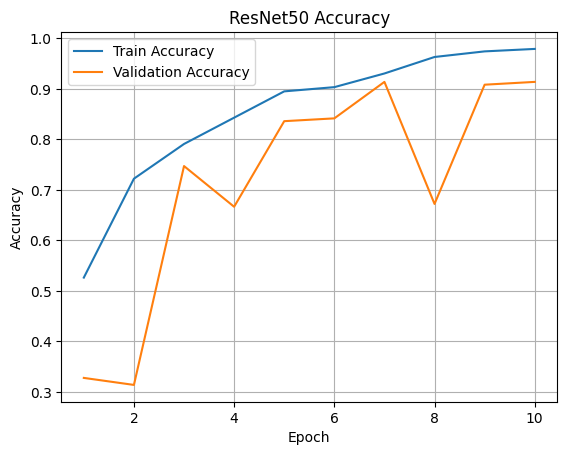

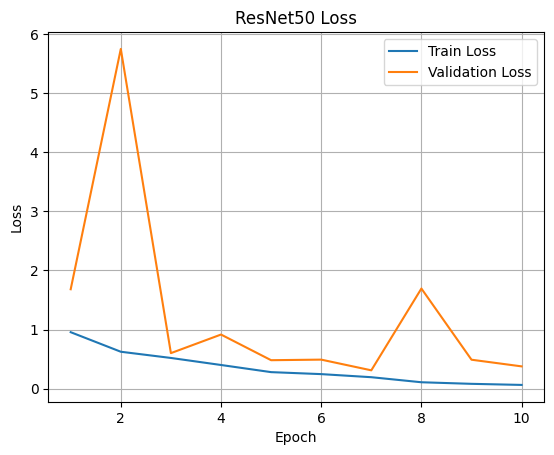

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import matplotlib.pyplot as plt

epochs = 10

resnet50.eval()
all_preds = []
all_labels = []
correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = resnet50(images)
        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Convert to numpy arrays
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

# Compute metrics
resnet_metrics = {
    'Accuracy': round(correct / total, 2),
    'Precision': round(precision_score(y_true, y_pred, average='weighted'), 4),
    'Recall': round(recall_score(y_true, y_pred, average='weighted'), 4),
    'F1 Score': round(f1_score(y_true, y_pred, average='weighted'), 4)
}

# Print metrics
print("ResNet50 Evaluation Metrics:")
for key, value in resnet_metrics.items():
    if key != 'Model':
        print(f"{key}: {value}")

# Accuracy plot
plt.plot(range(1, epochs+1), rn_train_accuracies, label='Train Accuracy')
plt.plot(range(1, epochs+1), rn_val_accuracies, label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss plot
plt.plot(range(1, epochs+1), rn_train_losses, label='Train Loss')
plt.plot(range(1, epochs+1), rn_val_losses, label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Loss")
plt.legend()
plt.grid(True)
plt.show()

**XCEPTION**

2025-10-21 15:57:54.637821: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1761062274.857846      37 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1761062274.911852      37 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Found 1440 images belonging to 3 classes.
Found 360 images belonging to 3 classes.
Class Weights: {0: 1.0, 1: 1.0, 2: 1.0}


I0000 00:00:1761062287.624047      37 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10668 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1761062287.624730      37 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

...

 1/90 ━━━━━━━━━━━━━━━━━━━━ 27:47 19s/step - accuracy: 0.2500 - loss: 1.2122

I0000 00:00:1761062309.347080     117 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


90/90 ━━━━━━━━━━━━━━━━━━━━ 45s 293ms/step - accuracy: 0.4821 - loss: 1.0192 - val_accuracy: 0.6722 - val_loss: 0.7104
Epoch 2/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 16s 181ms/step - accuracy: 0.6813 - loss: 0.6831 - val_accuracy: 0.7194 - val_loss: 0.5908
Epoch 3/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 16s 173ms/step - accuracy: 0.7692 - loss: 0.5468 - val_accuracy: 0.7528 - val_loss: 0.5364
Epoch 4/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 15s 170ms/step - accuracy: 0.7635 - loss: 0.5131 - val_accuracy: 0.7528 - val_loss: 0.4906
Epoch 5/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 15s 171ms/step - accuracy: 0.7892 - loss: 0.4744 - val_accuracy: 0.7694 - val_loss: 0.4749
Epoch 6/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 16s 175ms/step - accuracy: 0.7899 - loss: 0.4560 - val_accuracy: 0.7889 - val_loss: 0.4482
Epoch 7/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 16s 178ms/step - accuracy: 0.8192 - loss: 0.4258 - val_accuracy: 0.7861 - val_loss: 0.4349
Epoch 8/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 16s 176ms/step - accuracy: 0.8165 - loss: 0.4003 - val_accuracy: 0.788

E0000 00:00:1761062525.198751     118 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1761062525.412844     118 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1761062526.821354     118 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1761062527.011676     118 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1761062528.095509     118 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:0

90/90 ━━━━━━━━━━━━━━━━━━━━ 113s 587ms/step - accuracy: 0.5837 - loss: 1.1312 - val_accuracy: 0.7694 - val_loss: 0.4858
Epoch 2/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 46s 514ms/step - accuracy: 0.8236 - loss: 0.4361 - val_accuracy: 0.7750 - val_loss: 0.4629
Epoch 3/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 46s 515ms/step - accuracy: 0.9037 - loss: 0.2702 - val_accuracy: 0.7889 - val_loss: 0.4339
Epoch 4/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 46s 514ms/step - accuracy: 0.9322 - loss: 0.2200 - val_accuracy: 0.8000 - val_loss: 0.4220
Epoch 5/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 47s 517ms/step - accuracy: 0.9656 - loss: 0.1262 - val_accuracy: 0.8500 - val_loss: 0.3527


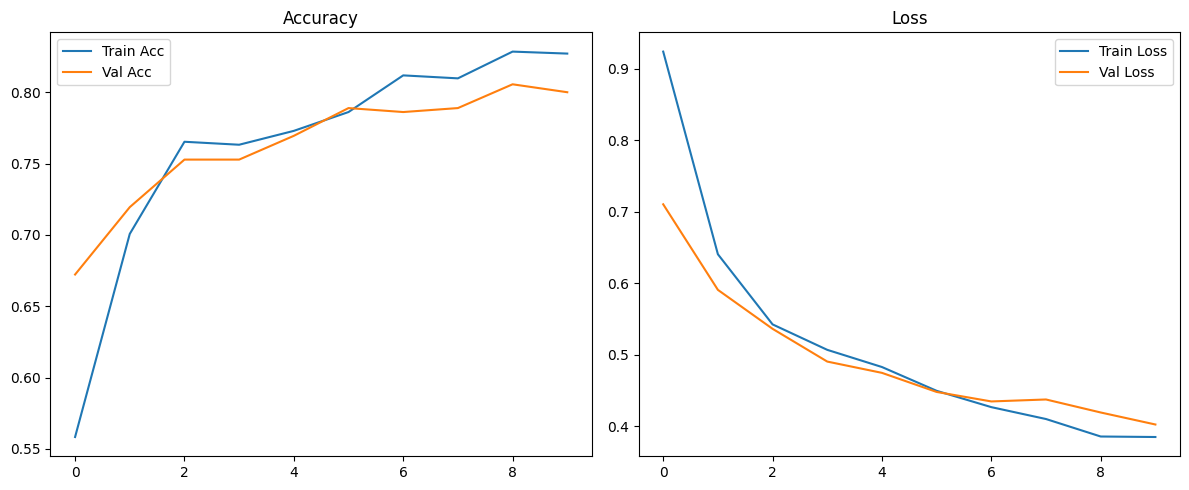

23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 296ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.81      0.79      0.80       120
Malignant cases       0.97      0.97      0.97       120
   Normal cases       0.78      0.79      0.79       120

       accuracy                           0.85       360
      macro avg       0.85      0.85      0.85       360
   weighted avg       0.85      0.85      0.85       360



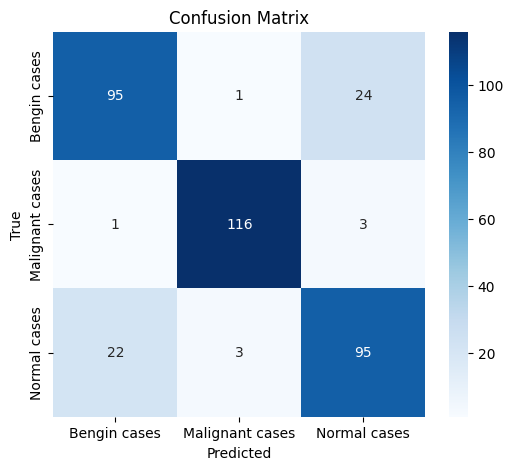

In [ ]:
# === IMPORT LIBRARIES ===
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB4, Xception
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# === SETUP ===
BATCH_SIZE = 16
IMG_SIZE = (299,299)  # EfficientNetB4 input size
EPOCHS = 10
DATASET_PATH = "/kaggle/working/balanced_dataset"  # <-- update if needed

# === DATA LOADING ===
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    subset='training',
    shuffle=True
)

val_gen = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    subset='validation',
    shuffle=False
)

# === CLASS WEIGHT HANDLING ===
y_train = train_gen.classes
class_weights = compute_class_weight(class_weight='balanced',
                                     classes=np.unique(y_train),
                                     y=y_train)
class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights)

# === Xception MODEL ===
base_model = Xception(include_top=False,
                            input_shape=IMG_SIZE + (3,),
                            weights='imagenet')

# Freeze base model initially
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(train_gen.num_classes, activation='softmax')(x)

xception_model = Model(inputs=base_model.input, outputs=output)

xception_model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

xception_model.summary()

# === TRAIN MODEL ===
history = xception_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    class_weight=class_weights
)

# === UNFREEZE & FINE-TUNE === (Optional)
base_model.trainable = True
xception_model.compile(optimizer=Adam(learning_rate=1e-5),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

fine_tune_epochs = 5
history_fine = xception_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=fine_tune_epochs,
    class_weight=class_weights
)

# === METRICS: ACCURACY + LOSS PLOTS ===
def plot_history(hist):
    acc = hist.history['accuracy']
    val_acc = hist.history['val_accuracy']
    loss = hist.history['loss']
    val_loss = hist.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Train Acc')
    plt.plot(epochs_range, val_acc, label='Val Acc')
    plt.legend()
    plt.title('Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Train Loss')
    plt.plot(epochs_range, val_loss, label='Val Loss')
    plt.legend()
    plt.title('Loss')

    plt.tight_layout()
    plt.show()

plot_history(history)
xception_preds_prob = xception_model.predict(val_gen)
xception_preds = np.argmax(xception_preds_prob, axis=1)  # predicted class indices
xception_labels = val_gen.classes  # ground truth


# === EVALUATE METRICS: Precision, Recall, F1 ===
y_true = val_gen.classes
y_pred = xception_model.predict(val_gen)
y_pred_labels = np.argmax(y_pred, axis=1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred_labels, target_names=list(val_gen.class_indices.keys())))

# === CONFUSION MATRIX ===
cm = confusion_matrix(y_true, y_pred_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=val_gen.class_indices.keys(),
            yticklabels=val_gen.class_indices.keys())
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# === PREDICTIONS ===
val_gen.reset()
pred_probs = xception_model.predict(val_gen, verbose=1)
y_pred = np.argmax(pred_probs, axis=1)
y_true = val_gen.classes

# === METRICS ===
xception_metrics = {
    'Accuracy': round(accuracy_score(y_true, y_pred), 4),
    'Precision': round(precision_score(y_true, y_pred, average='weighted'), 4),
    'Recall': round(recall_score(y_true, y_pred, average='weighted'), 4),
    'F1 Score': round(f1_score(y_true, y_pred, average='weighted'), 4)
}

# === PRINT METRICS ===
print("Xception Evaluation Metrics:")
for key, value in xception_metrics.items():
    print(f"{key}: {value}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 133ms/step
Xception Evaluation Metrics:
Accuracy: 0.85
Precision: 0.8501
Recall: 0.85
F1 Score: 0.85


**RestNet+**

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.applications.resnet50 import preprocess_input  # <-- Missing import

# Dataset path
dataset_path = "/kaggle/working/balanced_dataset"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10  # Lower initially for quick iteration

# --- DATA GENERATORS ---
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
).flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    subset='training',
    shuffle=True
)

val_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
).flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    subset='validation',
    shuffle=False
)

# --- CLASS WEIGHTS ---
y_train = train_gen.classes
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights)

Found 1440 images belonging to 3 classes.
Found 360 images belonging to 3 classes.
Class Weights: {0: 1.0, 1: 1.0, 2: 1.0}


In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, BatchNormalization

# Load pretrained ResNet50
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# --- FREEZE BOTTOM LAYERS ---
base_model.trainable = True
for layer in base_model.layers[:-50]:  # Only fine-tune top 50 layers
    layer.trainable = False

# --- CUSTOM CLASSIFIER ---
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)
predictions = Dense(train_gen.num_classes, activation='softmax')(x)

model_resnet = Model(inputs=base_model.input, outputs=predictions)

# --- COMPILE MODEL ---
model_resnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # Lower LR for fine-tuning
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_resnet.summary()

# --- CALLBACKS ---
callbacks = [
    EarlyStopping(patience=3, restore_best_weights=True),
    ModelCheckpoint("best_resnet_fine.h5", save_best_only=True)
]

# --- TRAIN MODEL ---
history_resnet = model_resnet.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,114,051 (91.99 MB)

 Trainable params: 17,476,355 (66.67 MB)

 Non-trainable params: 6,637,696 (25.32 MB)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 54s 400ms/step - accuracy: 0.5188 - loss: 1.3229 - val_accuracy: 0.3917 - val_loss: 1.2600
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 10s 222ms/step - accuracy: 0.8536 - loss: 0.3544 - val_accuracy: 0.6306 - val_loss: 0.7332
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 10s 221ms/step - accuracy: 0.9253 - loss: 0.2006 - val_accuracy: 0.8500 - val_loss: 0.4631
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 10s 215ms/step - accuracy: 0.9613 - loss: 0.1286 - val_accuracy: 0.9056 - val_loss: 0.3159
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 10s 214ms/step - accuracy: 0.9717 - loss: 0.1085 - val_accuracy: 0.9306 - val_loss: 0.2333
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 10s 211ms/step - accuracy: 0.9739 - loss: 0.0848 - val_accuracy: 0.9278 - val_loss: 0.1912
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 10s 210ms/step - accuracy: 0.9843 - loss: 0.0598 - val_accuracy: 0.9361 - val_loss: 0.1613
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 10s 211ms/step - accuracy: 0.9908 - loss: 0.0470 - val_accu

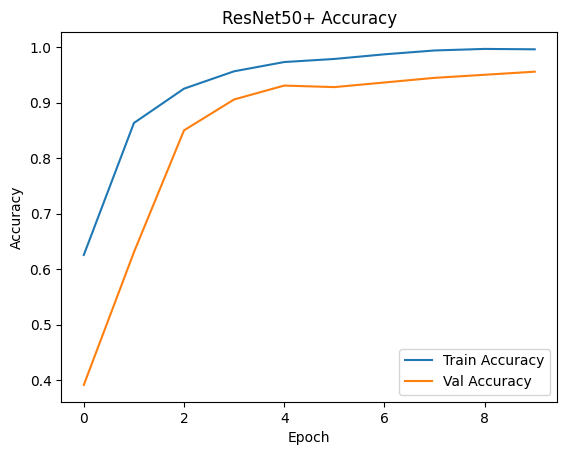

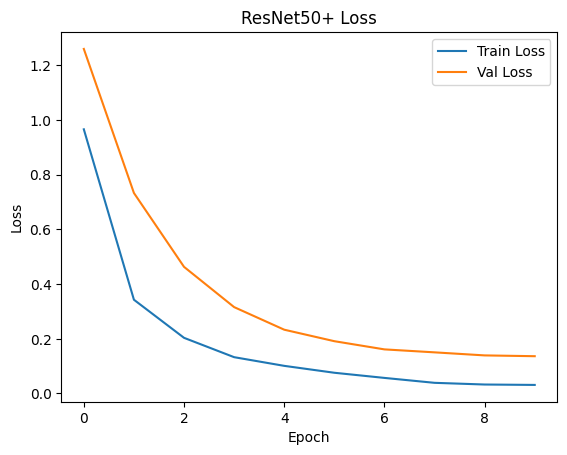

12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 484ms/step


In [ ]:
def plot_metrics(history, model_name="Model"):


    # Accuracy
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'{model_name} Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

    # Loss
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'{model_name} Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

plot_metrics(history_resnet, "ResNet50+")
# Generate predictions for ResNet+ for Max Voting
val_gen.reset()
resnet_plus_preds_prob = model_resnet.predict(val_gen)
resnet_plus_preds = np.argmax(resnet_plus_preds_prob, axis=1)
resnet_plus_labels = val_gen.classes

📊 ResNet50+ Evaluation Metrics:
Accuracy : 0.9556
Precision: 0.9562
Recall   : 0.9556
F1 Score : 0.9550

Detailed Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.94      0.97      0.96       120
Malignant cases       0.96      1.00      0.98       120
   Normal cases       0.97      0.89      0.93       120

       accuracy                           0.96       360
      macro avg       0.96      0.96      0.96       360
   weighted avg       0.96      0.96      0.96       360



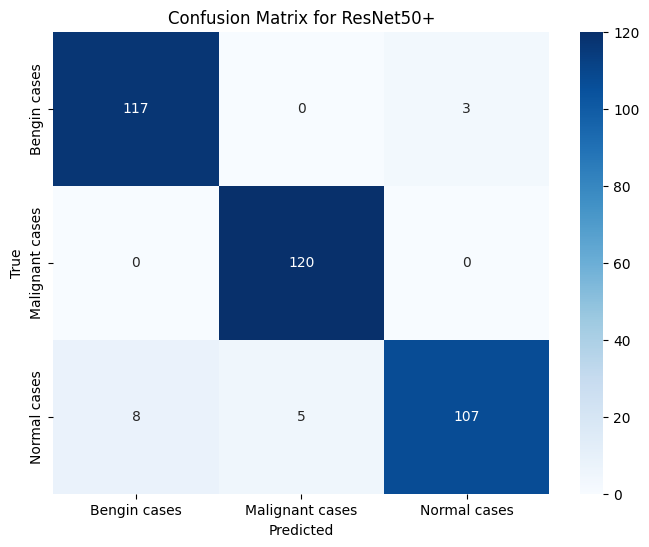

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import seaborn as sns

# --- METRIC CALCULATION ---
accuracy = accuracy_score(resnet_plus_labels, resnet_plus_preds)
precision = precision_score(resnet_plus_labels, resnet_plus_preds, average='weighted')
recall = recall_score(resnet_plus_labels, resnet_plus_preds, average='weighted')
f1 = f1_score(resnet_plus_labels, resnet_plus_preds, average='weighted')

print(f"📊 ResNet50+ Evaluation Metrics:")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

# --- OPTIONAL: Detailed Report ---
print("\nDetailed Classification Report:")
print(classification_report(resnet_plus_labels, resnet_plus_preds, target_names=list(val_gen.class_indices.keys())))

# --- OPTIONAL: Confusion Matrix ---
cm = confusion_matrix(resnet_plus_labels, resnet_plus_preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=val_gen.class_indices.keys(),
            yticklabels=val_gen.class_indices.keys())
plt.title('Confusion Matrix for ResNet50+')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


**CoAtNet**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 78.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 58.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 46.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 7.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 15.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 69.5 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installe

/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2225: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2225: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

Using device: cuda
Training samples: 1440
Validation samples: 360
Classes: ['Bengin cases', 'Malignant cases', 'Normal cases']
Class weights: tensor([1., 1., 1.], device='cuda:0')


model.safetensors:   0%|          | 0.00/110M [00:00<?, ?B/s]


Total parameters: 26,668,869
Trainable parameters: 9,540,415

Starting CoAtNet Training
Epoch [ 1/10] | Train Loss: 0.7528 | Train Acc: 0.6132 | Val Loss: 0.4451 | Val Acc: 0.8056
Epoch [ 2/10] | Train Loss: 0.4076 | Train Acc: 0.8208 | Val Loss: 0.2841 | Val Acc: 0.8917
Epoch [ 3/10] | Train Loss: 0.2537 | Train Acc: 0.8924 | Val Loss: 0.1920 | Val Acc: 0.9139
Epoch [ 4/10] | Train Loss: 0.2366 | Train Acc: 0.9049 | Val Loss: 0.1569 | Val Acc: 0.9417
Epoch [ 5/10] | Train Loss: 0.1216 | Train Acc: 0.9576 | Val Loss: 0.1318 | Val Acc: 0.9556
Epoch [ 6/10] | Train Loss: 0.0757 | Train Acc: 0.9778 | Val Loss: 0.0726 | Val Acc: 0.9694
Epoch [ 7/10] | Train Loss: 0.0512 | Train Acc: 0.9833 | Val Loss: 0.0455 | Val Acc: 0.9861
Epoch [ 8/10] | Train Loss: 0.0337 | Train Acc: 0.9889 | Val Loss: 0.0376 | Val Acc: 0.9833
Epoch [ 9/10] | Train Loss: 0.0270 | Train Acc: 0.9903 | Val Loss: 0.0277 | Val Acc: 0.9889
Epoch [10/10] | Train Loss: 0.0289 | Train Acc: 0.9924 | Val Loss: 0.0284 | Val Acc

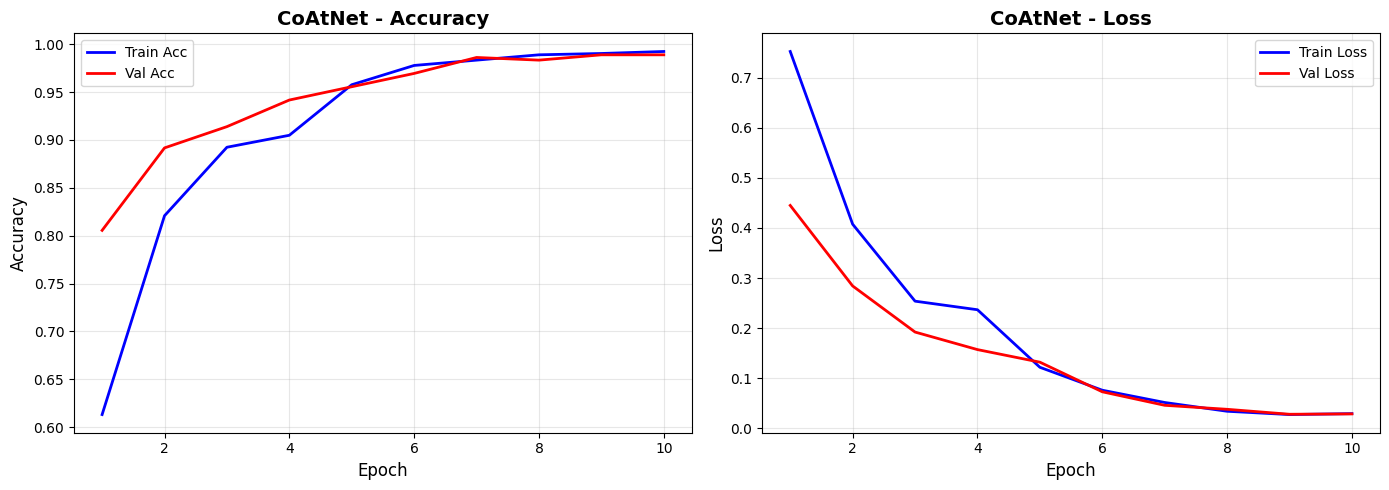


🔹 CoAtNet Final Evaluation Metrics 🔹
Accuracy:  0.9889
Precision: 0.9892
Recall:    0.9889
F1 Score:  0.9889

📊 Classification Report:
                 precision    recall  f1-score   support

   Bengin cases     0.9677    1.0000    0.9836       120
Malignant cases     1.0000    1.0000    1.0000       120
   Normal cases     1.0000    0.9667    0.9831       120

       accuracy                         0.9889       360
      macro avg     0.9892    0.9889    0.9889       360
   weighted avg     0.9892    0.9889    0.9889       360



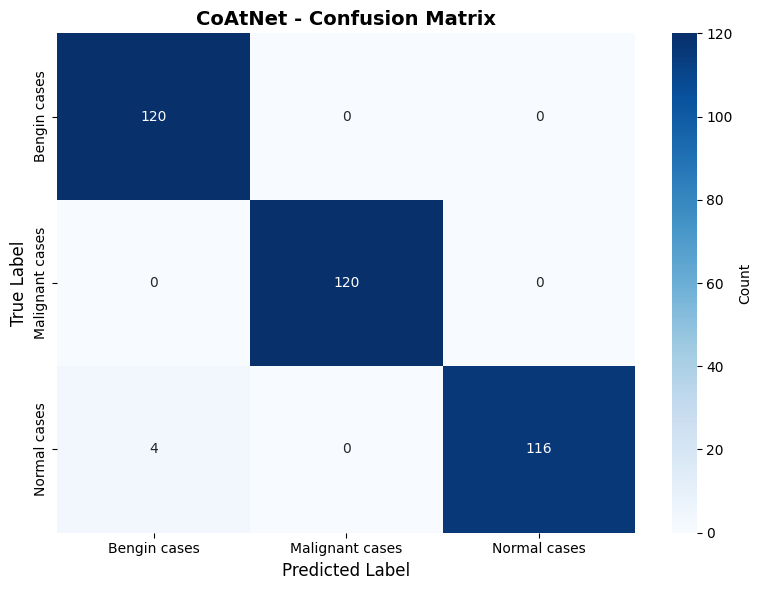


🔸 Generating Predictions for Ensemble
CoAtNet predictions shape: (360,)
CoAtNet labels shape: (360,)
Total validation samples: 360

Prediction distribution:
  Class 0 (Bengin cases): 124 samples
  Class 1 (Malignant cases): 120 samples
  Class 2 (Normal cases): 116 samples

CoAtNet model ready for ensemble!

 Model saved to 'coatnet_complete.pth'


In [ ]:
!pip install timm -q

import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
import timm
import numpy as np
from PIL import Image
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


# CRITICAL FIX: Use ImageDataGenerator validation split logic


def get_validation_split_indices(dataset_path, validation_split=0.2, seed=None):
    """
    Replicate TensorFlow's ImageDataGenerator validation_split behavior.
    This ensures CoAtNet uses the SAME validation set as TensorFlow models.
    """
    class_names = sorted(os.listdir(dataset_path))
    class_names = [c for c in class_names if os.path.isdir(os.path.join(dataset_path, c))]

    all_files = []
    all_labels = []

    for class_idx, class_name in enumerate(class_names):
        class_dir = os.path.join(dataset_path, class_name)
        files = sorted([f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

        for f in files:
            all_files.append(os.path.join(class_dir, f))
            all_labels.append(class_idx)

    # Calculate split point for EACH class (mimics TF behavior)
    train_files, val_files = [], []
    train_labels, val_labels = [], []

    for class_idx, class_name in enumerate(class_names):
        class_dir = os.path.join(dataset_path, class_name)
        files = sorted([f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

        # TensorFlow's validation_split takes the LAST validation_split% of each class
        num_files = len(files)
        split_index = int(num_files * (1 - validation_split))

        train_class_files = files[:split_index]
        val_class_files = files[split_index:]

        for f in train_class_files:
            train_files.append(os.path.join(class_dir, f))
            train_labels.append(class_idx)

        for f in val_class_files:
            val_files.append(os.path.join(class_dir, f))
            val_labels.append(class_idx)

    return train_files, train_labels, val_files, val_labels, class_names


# Custom Dataset that works with file paths
class FilePathDataset(Dataset):
    def __init__(self, file_paths, labels, transform=None):
        self.file_paths = file_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img_path = self.file_paths[idx]
        label = self.labels[idx]

        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label



# Configuration


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

DATA_PATH = "/kaggle/working/balanced_dataset"
IMG_SIZE = 224
BATCH_SIZE = 32  # Match TensorFlow models
EPOCHS = 10
NUM_CLASSES = 3
LR = 1e-4

# Data Preparation - ALIGNED WITH TENSORFLOW


train_files, train_labels, val_files, val_labels, class_names = get_validation_split_indices(
    DATA_PATH, validation_split=0.2
)

print(f"Training samples: {len(train_files)}")
print(f"Validation samples: {len(val_files)}")
print(f"Classes: {class_names}")

# Define transforms
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Create datasets
train_dataset = FilePathDataset(train_files, train_labels, train_transform)
val_dataset = FilePathDataset(val_files, val_labels, val_transform)

# Create dataloaders - CRITICAL: shuffle=False for validation!
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Compute class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print(f"Class weights: {class_weights}")

criterion = nn.CrossEntropyLoss(weight=class_weights)


# Model Setup


base_model = timm.create_model('coatnet_0_rw_224', pretrained=True, num_classes=NUM_CLASSES)
coatnet_model = base_model.to(device)

optimizer = optim.AdamW(coatnet_model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# Optional: Use mixed precision training
scaler = torch.amp.GradScaler('cuda') if torch.cuda.is_available() else None

# Freeze early layers for better stability
for name, param in coatnet_model.named_parameters():
    if "blocks.0" in name or "blocks.1" in name:
        param.requires_grad = False

print(f"\nTotal parameters: {sum(p.numel() for p in coatnet_model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in coatnet_model.parameters() if p.requires_grad):,}")


# Training Loop

train_accs, val_accs, train_losses, val_losses = [], [], [], []
best_val_acc = 0.0

print("\n" + "="*60)
print("Starting CoAtNet Training")
print("="*60)

for epoch in range(EPOCHS):
    # Training phase
    coatnet_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()

        if scaler:
            with torch.amp.autocast('cuda'):
                outputs = coatnet_model(imgs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = coatnet_model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        running_loss += loss.item()
        _, preds = outputs.max(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_acc = correct / total
    train_loss = running_loss / len(train_loader)
    train_accs.append(train_acc)
    train_losses.append(train_loss)

    # Validation phase
    coatnet_model.eval()
    val_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = coatnet_model(imgs)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, preds = outputs.max(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_acc = correct / total
    val_loss = val_loss / len(val_loader)
    val_accs.append(val_acc)
    val_losses.append(val_loss)

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(coatnet_model.state_dict(), 'best_coatnet_model.pth')

    scheduler.step()

    print(f"Epoch [{epoch+1:2d}/{EPOCHS}] | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

print(f"\n Best Validation Accuracy: {best_val_acc:.4f}")

# Load best model
coatnet_model.load_state_dict(torch.load('best_coatnet_model.pth'))


# Plot Training History

epochs_range = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_range, train_accs, 'b-', label='Train Acc', linewidth=2)
ax1.plot(epochs_range, val_accs, 'r-', label='Val Acc', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('CoAtNet - Accuracy', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_range, train_losses, 'b-', label='Train Loss', linewidth=2)
ax2.plot(epochs_range, val_losses, 'r-', label='Val Loss', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('CoAtNet - Loss', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# =============================================================================
# Final Evaluation
# =============================================================================

coatnet_model.eval()
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

print("\n" + "="*60)
print("🔹 CoAtNet Final Evaluation Metrics 🔹")
print("="*60)
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred, average='weighted'):.4f}")
print(f"F1 Score:  {f1_score(y_true, y_pred, average='weighted'):.4f}")
print("="*60)

print("\n📊 Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Count'})
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('CoAtNet - Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# =============================================================================
# CRITICAL: Generate Predictions for Ensemble - ALIGNED WITH TF MODELS
# =============================================================================

print("\n" + "="*60)
print("🔸 Generating Predictions for Ensemble")
print("="*60)

coatnet_model.eval()
coatnet_preds = []
coatnet_labels = []

# CRITICAL: Use same batch size and order as TensorFlow models
with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        outputs = coatnet_model(imgs)
        _, preds = outputs.max(1)
        coatnet_preds.extend(preds.cpu().numpy())
        coatnet_labels.extend(labels.numpy())

coatnet_preds = np.array(coatnet_preds)
coatnet_labels = np.array(coatnet_labels)

print(f"CoAtNet predictions shape: {coatnet_preds.shape}")
print(f"CoAtNet labels shape: {coatnet_labels.shape}")
print(f"Total validation samples: {len(coatnet_preds)}")

# Verify predictions
unique, counts = np.unique(coatnet_preds, return_counts=True)
print(f"\nPrediction distribution:")
for cls, cnt in zip(unique, counts):
    print(f"  Class {cls} ({class_names[cls]}): {cnt} samples")

print("\nCoAtNet model ready for ensemble!")
print("="*60)


# BONUS: Save model for later use


# Save the entire model
torch.save({
    'model_state_dict': coatnet_model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'val_acc': best_val_acc,
    'class_names': class_names
}, 'coatnet_complete.pth')

print("\n Model saved to 'coatnet_complete.pth'")

<!-- **Max Voting Ensemble** -->

In [ ]:
# import numpy as np
# from scipy.stats import mode
# from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# # Ensure both arrays are the same length
# min_len = min(len(resnet_preds), len(xception_preds),len(resnet_plus_preds),len(cnn_gru_preds),len(coatnet_preds))
# resnet_preds = resnet_preds[:min_len]
# xception_preds = xception_preds[:min_len]
# resnet_plus_preds = resnet_plus_preds[:min_len]
# cnn_gru_preds = cnn_gru_preds[:min_len]
# coatnet_preds = coatnet_preds[:min_len]
# ensemble_labels = cnn_gru_labels[:min_len]# ground truth

# # Stack predictions
# combined_preds = np.vstack([resnet_preds, xception_preds,resnet_plus_preds,cnn_gru_preds,
#     coatnet_preds])

# # Max Voting (mode across models)
# from scipy.stats import mode
# ensemble_preds, _ = mode(combined_preds, axis=0)
# ensemble_preds = ensemble_preds.flatten()


In [ ]:
# # Evaluation metrics
# accuracy = accuracy_score(ensemble_labels, ensemble_preds)
# precision = precision_score(ensemble_labels, ensemble_preds, average='weighted')
# recall = recall_score(ensemble_labels, ensemble_preds, average='weighted')
# f1 = f1_score(ensemble_labels, ensemble_preds, average='weighted')

# print("\n🔹 Ensemble (Max Voting) Evaluation 🔹")
# print(f"Accuracy:  {accuracy:.4f}")
# print(f"Precision: {precision:.4f}")
# print(f"Recall:    {recall:.4f}")
# print(f"F1 Score:  {f1:.4f}")

# # Optional: Detailed classification report
# print("\nClassification Report:")
# print(classification_report(ensemble_labels, ensemble_preds, target_names=list(val_gen.class_indices.keys())))

**MobileNetB2**

In [ ]:
# === MobileNetV2 ===
# ### Training

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight # Import compute_class_weight

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input # Use specific preprocess_input

# --- Configuration ---
data_dir = "/kaggle/working/balanced_dataset"
img_size = (224, 224) # MobileNetV2 default input size
batch_size = 32
epochs_mobilenet = 15 # Adjusted epochs - tune as needed
num_classes = 3

# --- Data Generators (using sparse for consistency) ---
# Use the specific preprocessing function for MobileNetV2
datagen_mobilenet = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_gen_mobilenet = datagen_mobilenet.flow_from_directory(
    data_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='sparse', # Changed to sparse
    subset='training',
    shuffle=True
)

val_gen_mobilenet = datagen_mobilenet.flow_from_directory(
    data_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='sparse', # Changed to sparse
    subset='validation',
    shuffle=False # Keep validation shuffle as False
)

# --- Model Definition ---
base_model_mobilenet = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model_mobilenet.trainable = False # Freeze base model

x = base_model_mobilenet.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x) # Regularization
# Add a dense layer before the final output
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x) # More regularization
output = Dense(num_classes, activation='softmax')(x) # Use num_classes

model_mobilenet = Model(inputs=base_model_mobilenet.input, outputs=output)

# --- Compile ---
model_mobilenet.compile(optimizer=Adam(learning_rate=1e-4),
              loss='sparse_categorical_crossentropy', # Changed loss
              metrics=['accuracy'])

model_mobilenet.summary()

# --- Training ---
# *** FIX: Re-calculate class_weights specifically for Keras/TF as a dictionary ***
y_train_mobilenet = train_gen_mobilenet.classes
class_weights_dict = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_mobilenet),
    y=y_train_mobilenet
)
class_weights_dict = dict(enumerate(class_weights_dict))
print("Using Keras Class Weights (Dictionary):", class_weights_dict)

# Use the dictionary version for Keras fit method
history_mobilenet = model_mobilenet.fit(
    train_gen_mobilenet,
    validation_data=val_gen_mobilenet,
    epochs=epochs_mobilenet,
    class_weight=class_weights_dict # Apply dictionary class weights
)

print("\n--- MobileNetV2 Training Complete ---")

Found 1440 images belonging to 3 classes.
Found 360 images belonging to 3 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Using Keras Class Weights (Dictionary): {0: 1.0, 1: 1.0, 2: 1.0}


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 275ms/step - accuracy: 0.4020 - loss: 1.4887 - val_accuracy: 0.6250 - val_loss: 0.7785
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 127ms/step - accuracy: 0.6083 - loss: 0.8136 - val_accuracy: 0.6861 - val_loss: 0.6597
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.6752 - loss: 0.6636 - val_accuracy: 0.7083 - val_loss: 0.5974
Epoch 4/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - accuracy: 0.7273 - loss: 0.5614 - val_accuracy: 0.7417 - val_loss: 0.5578
Epoch 5/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - accuracy: 0.7200 - loss: 0.5687 - val_accuracy: 0.7639 - val_loss: 0.5192
Epoch 6/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.7779 - loss: 0.4803 - val_accuracy: 0.7583 - val_loss: 0.4979
Epoch 7/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 125ms/step - accuracy: 0.7882 - loss: 0.4497 - val_accuracy: 0.7500 - val_loss: 0.4960
Epoch 8/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 125ms/step - accuracy: 0.8189 - loss: 0.4014 - val_accuracy: 0

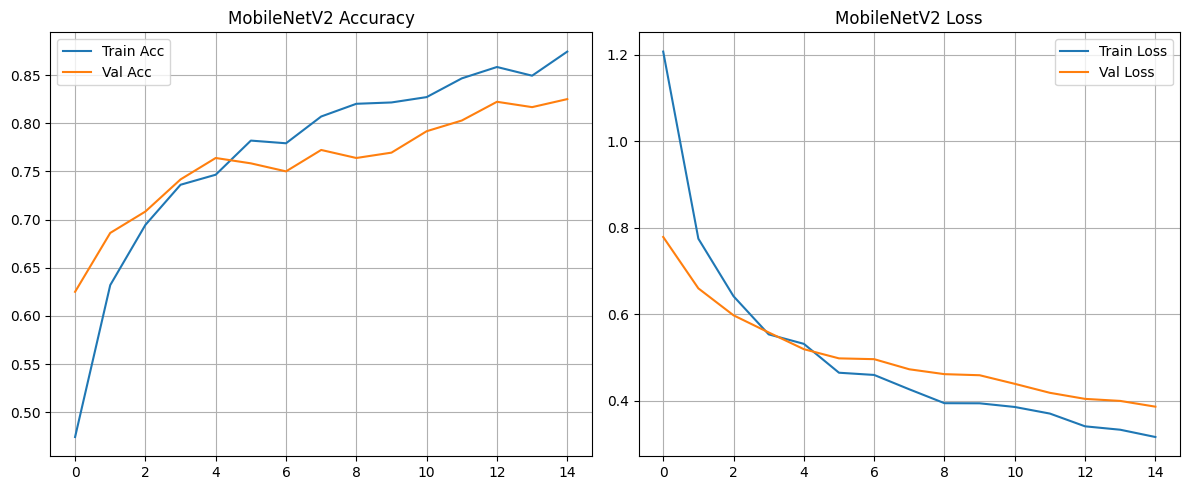

12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 405ms/step

MobileNetV2 Evaluation Metrics:
Accuracy: 0.825
Precision: 0.8207
Recall: 0.825
F1 Score: 0.8221

--- MobileNetV2 Evaluation Complete ---


In [ ]:
# === MobileNetV2 Evaluation ===

# Plot accuracy and loss
def plot_mobilenet_history(hist, model_name="MobileNetV2"):
    acc = hist.history['accuracy']
    val_acc = hist.history['val_accuracy']
    loss = hist.history['loss']
    val_loss = hist.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Train Acc')
    plt.plot(epochs_range, val_acc, label='Val Acc')
    plt.legend()
    plt.title(f'{model_name} Accuracy')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Train Loss')
    plt.plot(epochs_range, val_loss, label='Val Loss')
    plt.legend()
    plt.title(f'{model_name} Loss')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_mobilenet_history(history_mobilenet)

# Predict on validation data
val_gen_mobilenet.reset() # Important to reset generator
y_pred_probs_mobilenet = model_mobilenet.predict(val_gen_mobilenet)
mobilenet_preds = np.argmax(y_pred_probs_mobilenet, axis=1) # Predictions for ensemble
mobilenet_labels = val_gen_mobilenet.classes # Ground truth for ensemble

# Calculate and Print Metrics
mobilenet_accuracy = accuracy_score(mobilenet_labels, mobilenet_preds)
mobilenet_precision = precision_score(mobilenet_labels, mobilenet_preds, average='weighted')
mobilenet_recall = recall_score(mobilenet_labels, mobilenet_preds, average='weighted')
mobilenet_f1 = f1_score(mobilenet_labels, mobilenet_preds, average='weighted')

mobilenet_metrics = {
    'Accuracy': round(mobilenet_accuracy, 4),
    'Precision': round(mobilenet_precision, 4),
    'Recall': round(mobilenet_recall, 4),
    'F1 Score': round(mobilenet_f1, 4)
}

print("\nMobileNetV2 Evaluation Metrics:")
for key, value in mobilenet_metrics.items():
    print(f"{key}: {value}")

print("\n--- MobileNetV2 Evaluation Complete ---")

**Voting After 5**

In [ ]:
# === Max Voting Ensemble Code After 5 Model ===

import numpy as np
from scipy.stats import mode
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure all prediction arrays exist and have the correct names from previous cells
# (resnet_preds, xception_preds, resnet_plus_preds, mobilenet_preds, coatnet_preds)
# Also ensure the corresponding label arrays exist (e.g., mobilenet_labels)

# Find the minimum length among all prediction arrays to ensure consistency
min_len = min(len(resnet_preds), len(xception_preds), len(resnet_plus_preds), len(mobilenet_preds), len(coatnet_preds))

# Trim arrays to the minimum length
resnet_preds = resnet_preds[:min_len]
xception_preds = xception_preds[:min_len]
resnet_plus_preds = resnet_plus_preds[:min_len]
mobilenet_preds = mobilenet_preds[:min_len]
coatnet_preds = coatnet_preds[:min_len]

# Use one of the label arrays (trimmed) as the ground truth for the ensemble
# Ensure mobilenet_labels exists from the MobileNetV2 evaluation cell
ensemble_labels = mobilenet_labels[:min_len] # Use labels from one of the models

# Stack predictions vertically
combined_preds = np.vstack([
    resnet_preds,
    xception_preds,
    resnet_plus_preds,
    mobilenet_preds,
    coatnet_preds
])

# Max Voting (find the mode across the rows for each column)
# axis=0 calculates the mode vertically (across models for each sample)
ensemble_preds, _ = mode(combined_preds, axis=0, keepdims=False) # Use keepdims=False for older scipy versions if needed

# ensemble_preds might be shape (1, N), flatten it to (N,)
ensemble_preds = ensemble_preds.flatten()

print(f"Combined predictions shape: {combined_preds.shape}")
print(f"Ensemble predictions shape: {ensemble_preds.shape}")
print(f"Ensemble labels shape: {ensemble_labels.shape}")
print("\n--- Max Voting Setup Complete ---")

Combined predictions shape: (5, 360)
Ensemble predictions shape: (360,)
Ensemble labels shape: (360,)

--- Max Voting Setup Complete ---



🔹 Ensemble (Max Voting) Evaluation 🔹
Accuracy:  0.9389
Precision: 0.9388
Recall:    0.9389
F1 Score:  0.9383

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.91      0.94      0.93       120
Malignant cases       0.97      1.00      0.98       120
   Normal cases       0.94      0.88      0.91       120

       accuracy                           0.94       360
      macro avg       0.94      0.94      0.94       360
   weighted avg       0.94      0.94      0.94       360


--- Max Voting Evaluation Complete ---


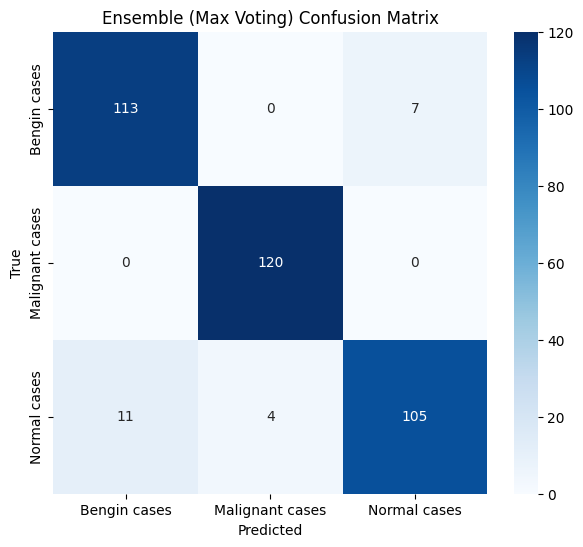

In [ ]:
# === Max Voting Evaluation Metrics ===

# Evaluation metrics
accuracy = accuracy_score(ensemble_labels, ensemble_preds)
precision = precision_score(ensemble_labels, ensemble_preds, average='weighted')
recall = recall_score(ensemble_labels, ensemble_preds, average='weighted')
f1 = f1_score(ensemble_labels, ensemble_preds, average='weighted')

print("\n🔹 Ensemble (Max Voting) Evaluation 🔹")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

# Optional: Detailed classification report
print("\nClassification Report:")
# Ensure val_gen (or a similar generator like val_gen_mobilenet) exists to get class names
# Using val_gen_mobilenet as it was defined in the MobileNetV2 block
print(classification_report(ensemble_labels, ensemble_preds, target_names=list(val_gen_mobilenet.class_indices.keys())))

# Optional: Confusion Matrix
print("\n--- Max Voting Evaluation Complete ---")
cm_ensemble = confusion_matrix(ensemble_labels, ensemble_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm_ensemble, annot=True, fmt='d', cmap='Blues',
            xticklabels=val_gen_mobilenet.class_indices.keys(),
            yticklabels=val_gen_mobilenet.class_indices.keys())
plt.title("Ensemble (Max Voting) Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()